# Bootstrap vs. analytic uncertainty: two real-data examples

This notebook compares analytic sampling uncertainty with a parametric bootstrap using two real historical datasets.

1. **Gaussian example:** Michelson's 1879 speed-of-light measurements.
2. **Poisson example:** Prussian cavalry horse-kick deaths.

Place these CSV files in the same folder as the notebook:

- `michelson_speed_of_light.csv`
- `prussian_horse_kicks.csv`


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, poisson

rng = np.random.default_rng(7)

# Part I — Gaussian model: Michelson's speed-of-light measurements

The Michelson data contain 100 measurements. The recorded speed is coded as

$
\text{speed} - 299000\ {\rm km/s}.
$

We model

$
X_i \overset{\rm iid}{\sim}\mathcal N(\mu,\sigma^2),
$

and estimate the population mean by

$
\hat\mu=\bar X.
$


In [2]:
michelson = pd.read_csv("michelson_speed_of_light.csv")
michelson.head()

,experiment,run,speed_minus_299000_km_s
0,1,1,850
1,1,2,740
2,1,3,900
3,1,4,1070
4,1,5,930


In [3]:
speed = michelson["speed_minus_299000_km_s"].to_numpy()

n = len(speed)
mu_hat = speed.mean()
s = speed.std(ddof=1)

print(f"n = {n}")
print(f"Estimated mean (coded) = {mu_hat:.2f}")
print(f"Estimated speed = {299000 + mu_hat:.2f} km/s")
print(f"Sample SD = {s:.2f}")

n = 100
Estimated mean (coded) = 852.40
Estimated speed = 299852.40 km/s
Sample SD = 79.01


In [4]:
print(" speed shape ", speed.shape)

 speed shape  (100,)


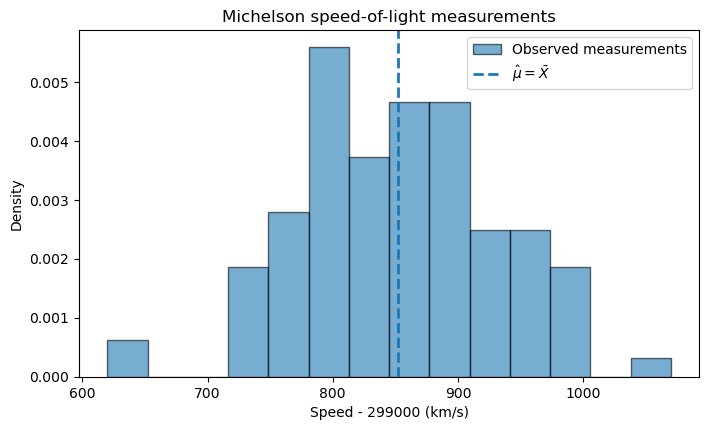

In [5]:
grid = np.linspace(speed.min()-50, speed.max()+50, 500)

plt.figure(figsize=(8,4.5))
plt.hist(speed, bins=14, density=True, alpha=0.6, edgecolor="black",
         label="Observed measurements")
#plt.plot(grid, norm.pdf(grid, loc=mu_hat, scale=s), lw=2.5,
#         label="Fitted Gaussian")
plt.axvline(mu_hat, ls="--", lw=2, label=r"$\hat\mu=\bar X$")
plt.xlabel("Speed - 299000 (km/s)")
plt.ylabel("Density")
plt.title("Michelson speed-of-light measurements")
plt.legend()
plt.show()


## Analytic uncertainty

For Gaussian observations,

$
\bar X\sim\mathcal N\left(\mu,\frac{\sigma^2}{n}\right).
$

Thus

$
\operatorname{SE}(\hat\mu)=\frac{\sigma}{\sqrt n}.
$

Since \(\sigma\) is unknown, we estimate it with \(S\):

$
\widehat{\operatorname{SE}}_{\rm analytic}
=
\frac{S}{\sqrt n}.
$


In [6]:
analytic_se_gauss = s / np.sqrt(n)
print(f"Analytic estimated SE = {analytic_se_gauss:.3f}")

Analytic estimated SE = 7.901


## Bootstrap

Non-parametric bootstrap: Resample the observed measurements **with replacement**, recompute the mean, and repeat.

Parametric bootstrap: Resample from the fitted distribution.

Here we use the **parametric bootstrap**: draw new datasets from the fitted $\mathcal N(\hat\mu, S^2)$, recompute the mean, and repeat.

In [7]:
B = 20_000

boot_mu = np.empty(B)

for b in range(B):
    x_star = rng.normal(loc=mu_hat, scale=s, size=n)
    boot_mu[b] = x_star.mean()

bootstrap_se_gauss = boot_mu.std(ddof=1)

print(f"Analytic estimated SE = {analytic_se_gauss:.3f}")
print(f"Parametric bootstrap SE = {bootstrap_se_gauss:.3f}")

Analytic estimated SE = 7.901
Parametric bootstrap SE = 7.926


In [8]:
speed.shape

(100,)

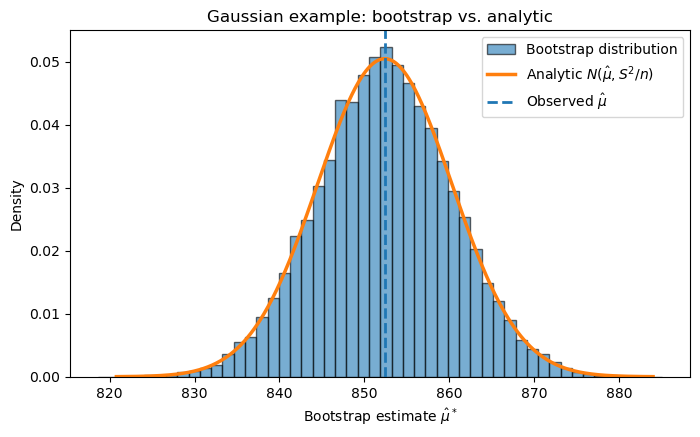

In [9]:
grid_mu = np.linspace(
    mu_hat - 4*analytic_se_gauss,
    mu_hat + 4*analytic_se_gauss,
    500
)

plt.figure(figsize=(8,4.5))
plt.hist(boot_mu, bins=50, density=True, alpha=0.6, edgecolor="black",
         label="Bootstrap distribution")
plt.plot(
    grid_mu,
    norm.pdf(grid_mu, loc=mu_hat, scale=analytic_se_gauss),
    lw=2.5,
    label=r"Analytic $N(\hat\mu,S^2/n)$"
)
plt.axvline(mu_hat, ls="--", lw=2, label=r"Observed $\hat\mu$")
plt.xlabel(r"Bootstrap estimate $\hat\mu^*$")
plt.ylabel("Density")
plt.title("Gaussian example: bootstrap vs. analytic")
plt.legend()
plt.show()


# Part II — Poisson model: Prussian cavalry horse-kick deaths

The second CSV contains 280 corps-year observations.

We model

$
X_i\overset{\rm iid}{\sim}\operatorname{Poisson}(\lambda).
$

Since

$
\mathbb E[X]=\lambda,
$

the method-of-moments estimator is

$
\hat\lambda=\bar X.
$


In [10]:
prussian = pd.read_csv("prussian_horse_kicks.csv")
prussian.head()

,observation_id,deaths_per_corps_year
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


In [11]:
deaths = prussian["deaths_per_corps_year"].to_numpy()

n_pois = len(deaths)
lambda_hat = deaths.mean()
sample_var = deaths.var(ddof=1)

print(f"n = {n_pois}")
print(f"Estimated lambda = {lambda_hat:.3f}")
print(f"Sample variance = {sample_var:.3f}")
print("For a Poisson model, mean and variance should be similar.")


n = 280
Estimated lambda = 0.700
Sample variance = 0.763
For a Poisson model, mean and variance should be similar.


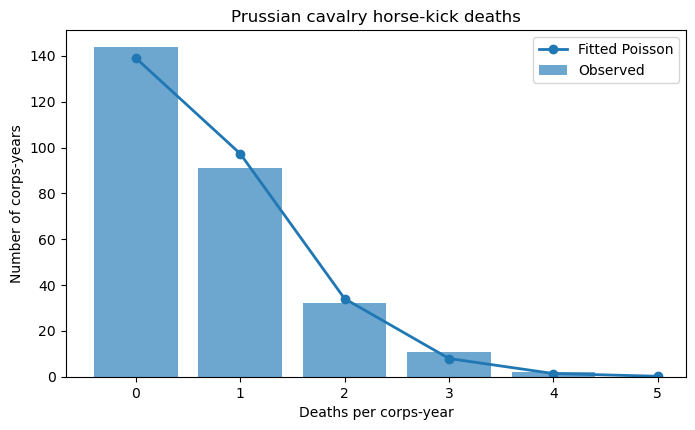

In [12]:
values, frequencies = np.unique(deaths, return_counts=True)
k = np.arange(0, 6)
expected = n_pois * poisson.pmf(k, mu=lambda_hat)

plt.figure(figsize=(8,4.5))
plt.bar(values, frequencies, alpha=0.65, label="Observed")
plt.plot(k, expected, "o-", lw=2, label="Fitted Poisson")
plt.xlabel("Deaths per corps-year")
plt.ylabel("Number of corps-years")
plt.title("Prussian cavalry horse-kick deaths")
plt.xticks(k)
plt.legend()
plt.show()


## Analytic uncertainty

Because independent Poisson random variables add,

$
\sum_{i=1}^n X_i\sim\operatorname{Poisson}(n\lambda).
$

Therefore,

$
\mathbb E[\hat\lambda]=\lambda,
\qquad
\operatorname{Var}(\hat\lambda)=\frac{\lambda}{n},
$

so

$
\operatorname{SE}(\hat\lambda)
=
\sqrt{\frac{\lambda}{n}}.
$

We estimate the unknown (\lambda\) by \(\hat\lambda\).


In [13]:
analytic_se_pois = np.sqrt(lambda_hat / n_pois)
print(f"Analytic estimated SE = {analytic_se_pois:.4f}")

Analytic estimated SE = 0.0500


## Bootstrap the Poisson rate

Draw new corps-year counts from the fitted Poisson distribution (parametric bootstrap) and recompute

$
\hat\lambda^*=\bar X^*.
$


In [16]:
boot_lambda = np.empty(B)

for b in range(B):
    #x_star = rng.choice(deaths, size=n_pois, replace=True)
    x_star = rng.poisson(lam=lambda_hat, size=n_pois)
    boot_lambda[b] = x_star.mean()

bootstrap_se_pois = boot_lambda.std(ddof=1)

print(f"Analytic estimated SE = {analytic_se_pois:.4f}")
print(f"Bootstrap SE          = {bootstrap_se_pois:.4f}")


Analytic estimated SE = 0.0500
Bootstrap SE          = 0.0500


## Compare with the exact fitted sampling distribution

Under the fitted Poisson model,

$
n\hat\lambda
\sim
\operatorname{Poisson}(n\hat\lambda_{\rm obs}).
$


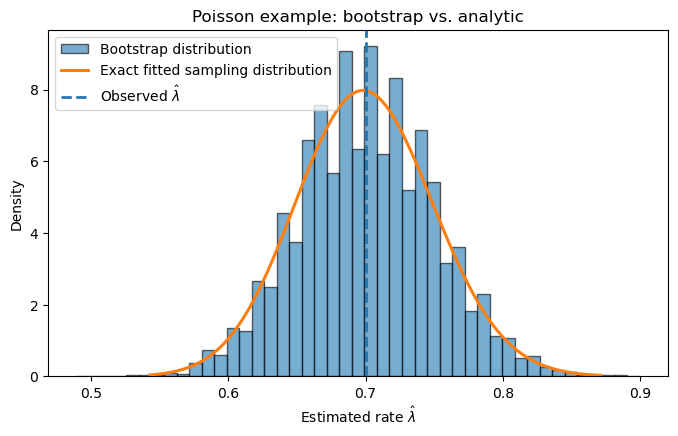

In [17]:
mean_sum = n_pois * lambda_hat
lo = int(poisson.ppf(0.0005, mean_sum))
hi = int(poisson.ppf(0.9995, mean_sum))
total_counts = np.arange(lo, hi+1)

lambda_grid = total_counts / n_pois
pmf = poisson.pmf(total_counts, mean_sum)
dx = 1 / n_pois

plt.figure(figsize=(8,4.5))
plt.hist(boot_lambda, bins=45, density=True, alpha=0.6, edgecolor="black",
         label="Bootstrap distribution")
plt.plot(lambda_grid, pmf/dx, lw=2.2,
         label="Exact fitted sampling distribution")
plt.axvline(lambda_hat, ls="--", lw=2, label=r"Observed $\hat\lambda$")
plt.xlabel(r"Estimated rate $\hat\lambda$")
plt.ylabel("Density")
plt.title("Poisson example: bootstrap vs. analytic")
plt.legend()
plt.show()
